# Lab 4: Towards quantum advantage

## Qiskit Fall Fest 2026 Warsaw

# Chapter 1: Classically verifiable problems: QAOA for partition problem

*Usage estimate of QPU time for the notebook: 5 min 30 seconds on a Heron r2 processor (NOTE: This is an estimate only. Your runtime might vary.)*

*The QPU usage estimate reflects only backend execution time. Queueing, calibration, and runtime session delays can extend total execution to several minutes, even for workloads using only seconds of QPU time.*

The [Quantum Advantage Tracker](https://quantum-advantage-tracker.github.io/) classifies quantum advantage demonstrations into three categories: classically verifiable problems, variational problems, and observable estimation. Examples include the $ \mathrm{Fe}_4\mathrm{S}_4$ molecule computation (variational) and the Loschmidt Echo calculation (observable estimation).

Now we turn to the first category: **classically verifiable problems**. These are optimization problems where we can efficiently verify if a quantum solution is correct, even if finding that solution classically is exponentially hard. This makes them ideal candidates for demonstrating quantum advantage, since we can prove the quantum computer found a good answer without needing an equally powerful classical computer to check it.

In this lab, we will explore the [Quantum Approximate Optimization Algorithm (QAOA)](https://quantum.cloud.ibm.com/learning/courses/quantum-computing-in-practice/utility-scale-qaoa) applied to the Partition Problem. QAOA is particularly promising because:
- It is designed for near-term quantum hardware (no error correction needed)
- Solutions are easy to verify classically
- It has the potential to demonstrate quantum advantage as we scale to larger problem sizes

The partition problem asks: given a set of numbers, can we split them into two groups with equal sums? While this sounds simple, it becomes exponentially harder as the problem size grows, making it a perfect testbed for quantum advantage. Let's see how QAOA tackles it!

## Track 1 local build — adaptation log (Sat Oct 24, 2026)

This is the **local working copy** (`lab_4a_track1_working.ipynb`); the original
`lab_4a.ipynb` is untouched. Everything that needs David's IBM Quantum account
is stubbed and marked **DAVID'S SESSION ONLY**:

- `save_account` / `check_progress` / all `grade_lab4a_*` cells — the grader
  endpoint rejects this VM (HTTP 403); they run in David's session.
- Hardware execution (IBM Runtime `Sampler`/`Estimator`, least-busy backend) —
  replaced locally by `AerSimulator` + qiskit-aer V2 primitives (ideal,
  noiseless). IBM-only options (dynamical decoupling, twirling, resilience /
  TREX / ZNE / PEC) are filled in as option objects for the hardware run but
  are no-ops on the simulator, so locally the §2 versions and §4 scenarios
  coincide up to shot noise. The mitigation comparison is a hardware result.
- All lab TODOs are filled (1a, 1b, 2a–2d, 3a–3c, 4a–4d). One API rename:
  opt-mapper 0.1.0 calls it `to_optimization_problem()` (was
  `to_quadratic_program()`); the objects produced are identical.
- Classical baselines for the entry live in `results/baselines-ladder.json`;
  the trained-QAOA benchmark in `results/qaoa-vs-baselines.json`
  (see `run_baselines.py` / `run_benchmark.py`).


### Install the necessary libraries

In [1]:
# ── LOCAL ADAPTATION ── Packages were installed once into ./venv
# (qiskit 2.6.1, qiskit-aer 0.18.0, qiskit-ibm-runtime 0.51.0,
# qfest-grader 0.3.0, mthree 3.0.0, qopt-best-practices 0.1.0,
# qiskit-addon-opt-mapper 0.1.0). The original %pip install cell is
# preserved in lab_4a.ipynb. Here we only verify versions.
import importlib.metadata as md
for pkg in ["qiskit", "qiskit-aer", "qiskit-ibm-runtime", "qfest-grader", "mthree"]:
    print(pkg, md.version(pkg))


qiskit 2.6.1
qiskit-aer 0.18.0
qiskit-ibm-runtime 0.51.0
qfest-grader 0.3.0
mthree 3.0.0


### Setting up the `utils` folder

Wether you use a local environment (such as [VSCode](https://code.visualstudio.com/)) or an online enviornment (such as [qBraid](https://www.qbraid.com/)), make sure that you place the `utils` folder in the same directory as the notebook. Otherwise you will receive a ModuleNotFoundError when you execute the Imports cell.

### Imports

In [2]:
from qfest_grader.challenges.warsaw_2026 import (
    check_progress,
    grade_lab4a_ex1a,
    grade_lab4a_ex1b,
    grade_lab4a_ex2a,
    grade_lab4a_ex2b,
    grade_lab4a_ex2c,
    grade_lab4a_ex2d,
    grade_lab4a_ex2,
    grade_lab4a_ex3a,
    grade_lab4a_ex3b,
    grade_lab4a_ex3c,
    grade_lab4a_ex4a,
    grade_lab4a_ex4b,
    grade_lab4a_ex4c,
    grade_lab4a_ex4d,
    grade_lab4a_ex4,
)

# Import libraries
import numpy as np
import matplotlib.pyplot as plt
from qiskit.quantum_info import SparsePauliOp

from scipy.optimize import minimize
import networkx as nx
from qiskit_ibm_runtime import (
    QiskitRuntimeService,
    Session,
    EstimatorV2 as Estimator,
    SamplerV2 as Sampler,
)
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime.options import SamplerOptions, EstimatorOptions
import mthree

from qiskit_addon_opt_mapper.applications import Maxcut
from qiskit_addon_opt_mapper.translators import to_ising
from qopt_best_practices.circuit_library import annotated_qaoa_ansatz
from qopt_best_practices.transpilation import UnrollBoxes

from qiskit.transpiler import CouplingMap
from qopt_best_practices.transpilation.generate_preset_qaoa_pass_manager import (
    generate_preset_qaoa_pass_manager,
)
from qiskit.transpiler.passes.routing.commuting_2q_gate_routing import SwapStrategy
from itertools import combinations

# Import utils
from utils.functions import plot_partition_graph, analyze_partition_result
from utils.functions import (
    analyze_error_mitigation_result,
    compare_error_mitigation_methods,
    plot_error_mitigation_comparison,
    print_comparison_summary,
)
from utils.functions import get_partitions, calc_cut_size

from random import sample

# Set seed for reproducibility
seed = 42

In [ ]:
# ── Grader account ────────────────────────────────────────────────────────────
# Original cell:
# from qfest_grader import save_account
# save_account("<your email>")
print("SKIPPED (local phase): save_account — run in David's session")


SKIPPED (local phase): save_account — run in David's session


Throughout the Lab you can use the `check_progress` function to see how many exercises you have completed:

In [ ]:
# check_progress()  
print("SKIPPED (local phase): check_progress — run in David's session")


SKIPPED (local phase): check_progress — run in David's session


We choose the backend

In [ ]:
## REMOVE THIS CELL AFTER SUBMITING LIVE IBM QUANTUM CREDENTIALS!
from qiskit_ibm_runtime import QiskitRuntimeService
QiskitRuntimeService.save_account(token="<your API key>", instance="<your instance CRN>")


In [ ]:
# ── LOCAL ADAPTATION ── Original cell created QiskitRuntimeService() and
# picked the least-busy 156+ qubit hardware backend. The local phase runs on
# an ideal AerSimulator instead. The Runtime service + hardware backend are
# reserved for USER's session (ONE careful hardware pass; Open Plan budget).
from qiskit_aer import AerSimulator

backend = AerSimulator()
print(f"We are using {backend.name} (local ideal simulator stand-in)")


We are using aer_simulator (local ideal simulator stand-in)


Note that this lab is intended to be run on a QPU. However, if you run out of QPU time, you can still complete it using a simulator. To do so, uncomment the following cell

In [6]:
# Local phase note: the original lab suggests AerSimulator.from_backend(backend)
# as a fallback when QPU time runs out. Here the backend already IS an
# AerSimulator (see cell above), so no conversion is needed.


## The Partition Problem:

The Partition Problem seeks to divide a set of numbers into two groups such that the difference between their total sums is as small as possible, with the special case of zero difference corresponding to perfectly equal partitions. 
It has numerous real‑world applications across different areas, including logistics, finance, and resource allocation. We can illustrate this with a small day-to-day example.

Imagine you're packing groceries into two identical backpacks for a camping trip.
You have six items, each with a different weight:

- Milk bottle: 3 kg
- Flour bag: 5 kg
- Rice pack: 7 kg
- Watermelon: 9 kg
- Olive oil bottle: 11 kg
- Water pack: 13 kg

Your goal is to pack the groceries into the two backpacks so that both backpacks weigh exactly the same.
Can you do it?

While this may seem simple for a small number of items, the Partition Problem is an NP‑hard problem, which means that while it is straightforward to verify whether a proposed solution is correct, simply by summing the elements in each subset, it is computationally very difficult to actually find such a solution in the first place, as no efficient algorithm is known.


Mathematically, the Partition Problem can be formulated as an optimization task in which we aim to divide the set into two subsets that can be of different size and whose sums are as close as possible. This corresponds to minimizing the absolute difference between the sums of the two subsets:

$$\min_{S_1, S_2} \left| \sum_{a_i \in S_1} a_i - \sum_{a_j \in S_2} a_j \right|$$

For our simple example $S = \{3, 5, 7, 9, 11, 13\}$, the solution is:
- Backpack 1: $\{3, 5, 7, 9\}$ → 24 kg 
- Backpack 2: $\{11, 13\}$ → 24 kg

This is a valid partition because both subsets sum to 24 kg.

Finding this solution by hand was easy for 6 numbers, but what about 100? Or 1000?
For $n$ elements, there are $2^n$ possible partitions to check. For just 50 elements, that's over 1 quadrillion possibilities!


This is where **quantum computing** enters the story...


### From partition problem to Hamiltonian formalism

#### QUBO formalism

To try to solve this problem using a quantum computer, first we need to rewrite it as a Quadratic Unconstrained Binary Optimization (QUBO) problem.

#### Binary Encoding

Use binary variables $x_i \in \{0, 1\}$:
- $x_i = 0$ → element $a_i$ in subset $S_1$
- $x_i = 1$ → element $a_i$ in subset $S_2$

#### Objective Function

The cost (imbalance) between subsets:

$$C = \sum_{i: x_i=1} a_i - \sum_{i: x_i=0} a_i = \sum_{i=1}^n a_i(2x_i - 1)$$

We minimize $C^2$ to avoid absolute values:

$$\min_{x \in \{0,1\}^n} C^2 = \min_{x \in \{0,1\}^n} \left(\sum_{i=1}^n a_i(2x_i - 1)\right)^2$$

If we expand this, we can see that our cost function is going to represent a QUBO problem for our variables $x_i$.

### From QUBO to Ising Hamiltonian
Let us now try to rewrite this QUBO problem by using spin variables $z_i \in \{-1, +1\}$ instead of binary, related by:
$$x_i = \frac{1-z_i}{2}$$

Substituting into the cost:

$$C = \sum_{i=1}^n a_i(2x_i - 1) = -\sum_{i=1}^n a_i z_i$$

using $\left(\sum_i x_i\right)^2=\sum_i\sum_j x_i x_j$ and $x_i=a_i z_i$ we obtain:

$$C^2 = \sum_{i,j} a_i a_j z_i z_j$$

Splitting the double sum into the cases $i=j$ and $i\neq j$:

$$C^2=\sum_i a_i^2 z_i^2+\sum_{i\neq j} a_i a_j z_i z_j$$

Since Ising spins satisfy $z_i^2=1$ the first term becomes a constant:

$$\sum_i a_i^2 z_i^2 = \sum_i a_i^2$$

So

$$C^2= \sum_i a_i^2 + \sum_{i\neq j} a_i a_j z_i z_j$$

Using symmetry, each pair $(i,j)$ appears twice: $a_i a_j z_i z_j$ and $a_j a_i z_j z_i$; because they are identical, we can write:

$$\sum_{i\neq j} a_i a_j z_i z_j = 2\sum_{i<j} a_i a_j z_i z_j$$

Therefore

$$C^2= \underbrace{\sum_i a_i^2}_{\text{constant}} + 2\sum_{i<j} a_i a_j z_i z_j$$

Since constants do not affect the minimizer, we can drop them and obtain:

$$ C^2 = 2\sum_{i<j} a_i a_j z_i z_j$$

where the factor of 2 is often absorbed into the coupling coefficients or ignored because an overall scaling does not change the optimal bitstring. The only thing that matters for optimization is that the coupling between qubits $i$ and $j$ is proportional to $a_i a_j$. Replacing classical spins with Pauli-Z operators gives the cost Hamiltonian:

$$H_C = \sum_{i<j} a_i a_j Z_i Z_j$$

where each term's weight is the product of two numbers $a_i a_j$.
Now we can find the eigenvector of this Cost Hamiltonian by using the [QAOA algorithm](https://quantum.cloud.ibm.com/learning/courses/quantum-computing-in-practice/utility-scale-qaoa), which is what we will be doing in this Lab.

# 1. We define the partition problem example

In [7]:
# Define our partition problem
numbers = [3, 5, 7, 9, 11, 13]

n = len(numbers)

print(f"Numbers to partition: {numbers}")
print(f"Total sum: {sum(numbers)}")
print(f"Target sum per partition: {sum(numbers) / 2}")

Numbers to partition: [3, 5, 7, 9, 11, 13]
Total sum: 48
Target sum per partition: 24.0


<a id="exercise_1"></a>
<div class="alert alert-block alert-success">
    
<b>Exercise 1a: Define the graph that defines the partition problem </b> 

**Your Goal:** Define the graph that defines the partition problem.

In this first exercise, you will create a weighted graph representation of the partition problem. This is a crucial step in transforming the partition problem into a form that QAOA can solve.

**Background:** The partition problem can be mapped to a MaxCut problem on a complete graph. In this representation:
- Each number in our set represents a **node** in the graph
- Every pair of nodes is connected by an **edge**
- The **weight** of each edge is the product of the two numbers it connects


**Hint:** Use NetworkX's graph functions. You'll need to iterate through all pairs of nodes and add weighted edges.

</div>

Here are the links to [NetworkX documentation](https://networkx.org/documentation/stable/reference/index.html), [NetworkX graph class](https://networkx.org/documentation/stable/reference/classes/graph.html#overview), and a [NetworkX tutorial](https://networkx.org/documentation/stable/tutorial.html)

In [8]:
def build_partition_graph(numbers: list[int])  -> nx.Graph:
    """
    Create a complete weighted graph where edge weights are the product
    of the corresponding values in `numbers`.

    Parameters
    ----------
    numbers : list or sequence of numbers
        Values used to compute edge weights.

    Returns
    -------
    partition_graph : networkx.Graph
        Graph with n nodes and weighted edges.
    """
    n = len(numbers)
    nodes = range(n)
    # ---- TODO : Task 1a --- (filled, Track 1 build)
    # Create a complete graph where each node represents a number
    partition_graph = nx.complete_graph(n)
    # Add edges with weights = product of the two numbers
    # This encoding ensures that cutting between different-valued nodes
    # contributes more to the objective
    for i, j in combinations(range(n), 2):
        partition_graph.add_edge(i, j, weight=numbers[i] * numbers[j])
    # ---- end of TODO : Task 1a ---
    return partition_graph


partition_graph = build_partition_graph(numbers)


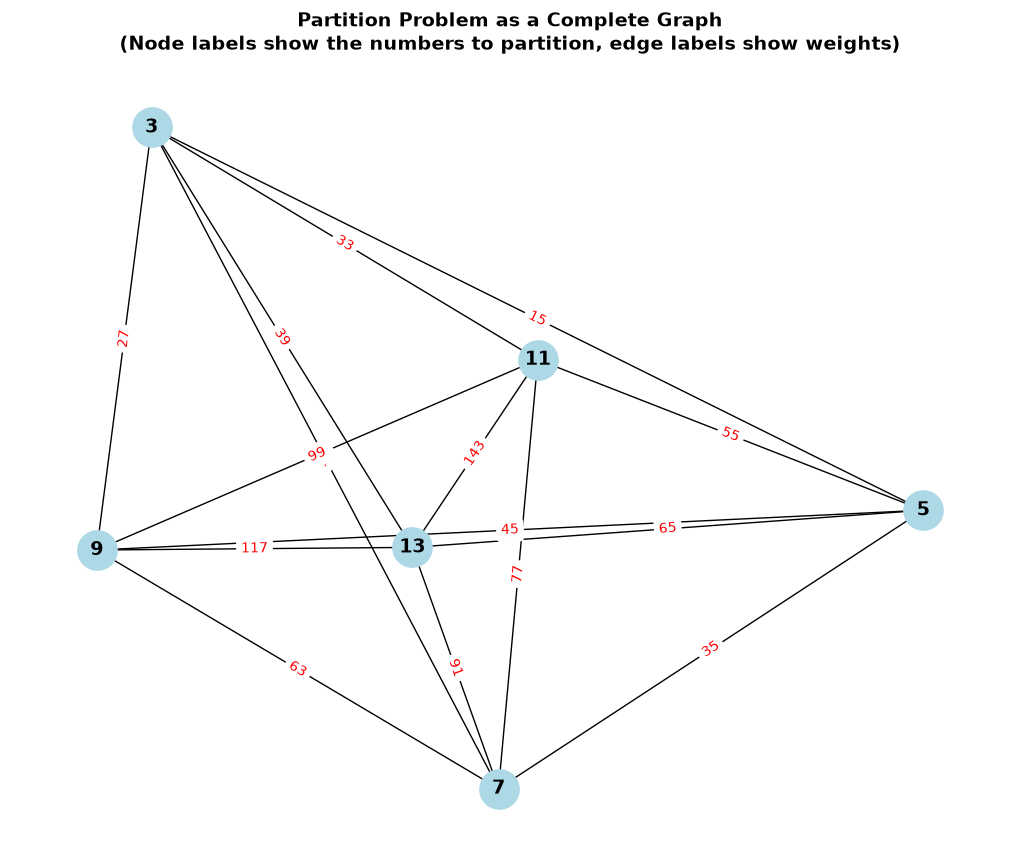


Each node represents a number from our set.
Edges connect all pairs, weighted by the product of the numbers.


In [9]:
plot_partition_graph(partition_graph, numbers, seed=seed, show=True)

In [ ]:
## Verify your answer ##
# Original call:
# grade_lab4a_ex1a(partition_graph)
print("SKIPPED (local phase): grade_lab4a_ex1a — run in David's session")


SKIPPED (local phase): grade_lab4a_ex1a — run in David's session


Now let's use QAOA to solve this partition problem by finding the MaxCut!

We'll convert the graph to a cost Hamiltonian, which in this case will be the partition Hamiltonian, and apply QAOA to find the optimal partition. To do that we encourage you to explore the [`qiskit_addon_opt_mapper`](https://qiskit.github.io/qiskit-addon-opt-mapper/) library and [`qopt_best_practices`](https://github.com/qiskit-community/qopt-best-practices) libraries to create the QAOA circuit and optimize its parameters.

<a id="exercise_1b"></a>
<div class="alert alert-block alert-success">
    
<b>Exercise 1b: From graph to Hamiltonian and quantum circuit </b> 

**Your Goal:** Convert the graph representation into the cost Hamiltonian and construct the QAOA circuit using the `qiskit_addon_opt_mapper`and `qopt_best_practices` libraries.

Note that the cost Hamiltonian is the partition Hamiltonian and needs to be a SparsePauliOp object.

In this exercise, you will transform the classical graph problem into a QAOA quantum circuit whose parameters we can optimize. This involves two key steps: creating the partition Hamiltonian that encodes the MaxCut objective, and building a parameterized quantum circuit.

**Hint:** Review the import statements at the top of the notebook to see which functions you might need.
Also take a look at the output of the [`to_ising`](https://github.com/Qiskit/qiskit-addon-opt-mapper/blob/main/qiskit_addon_opt_mapper/translators/ising.py#L24) function, and note that the function needs to take an `OptimizationProblem` input, not a [`Maxcut`](https://qiskit.github.io/qiskit-addon-opt-mapper/stubs/qiskit_addon_opt_mapper.applications.Maxcut.html#qiskit_addon_opt_mapper.applications.Maxcut) class.

</div>


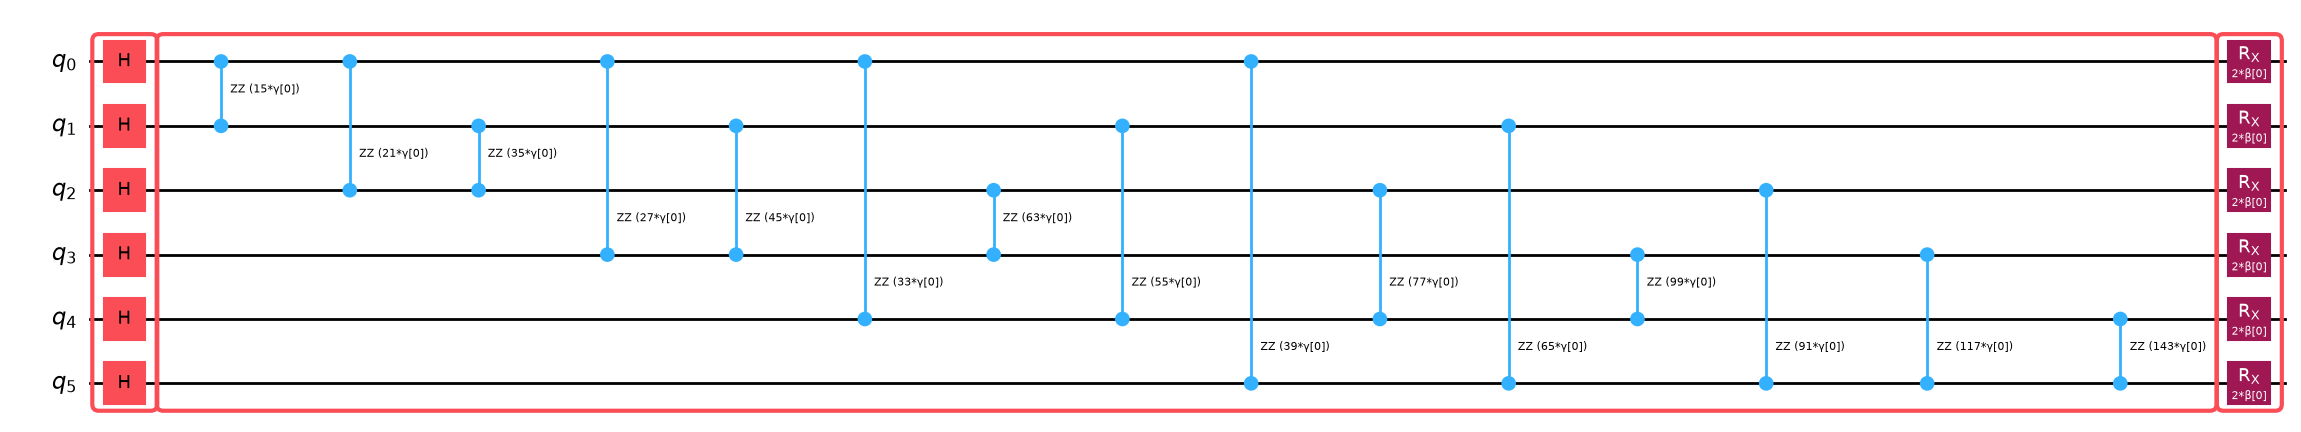

In [11]:
layers = 1

# ---- TODO : Task 1b --- (filled, Track 1 build)
# NOTE: qiskit-addon-opt-mapper 0.1.0 renamed to_quadratic_program() to
# to_optimization_problem(); the objects produced are identical.
maxcut = Maxcut(partition_graph)
partition_hamiltonian, _offset = to_ising(maxcut.to_optimization_problem())
# Note that we created an annotated_qaoa_ansatz circuit where the individual QAOA cost
# and QAOA mixer layers are annotated for improved transpilation
circuit = annotated_qaoa_ansatz(partition_hamiltonian, reps=layers)

# ---- end of TODO : Task 1b ---

# Now we draw the circuit and add the measurements for sampling
circuit_sampler = circuit.copy()
circuit_sampler.measure_all()
circuit.draw(idle_wires=False, fold=-1, output="mpl")

In [ ]:
## Verify your answer ##
# Run session after the hardware pass. Original call:
# grade_lab4a_ex1b(partition_hamiltonian, circuit)
print("SKIPPED (local phase): grade_lab4a_ex1b — run in David's session")


SKIPPED (local phase): grade_lab4a_ex1b — run in David's session


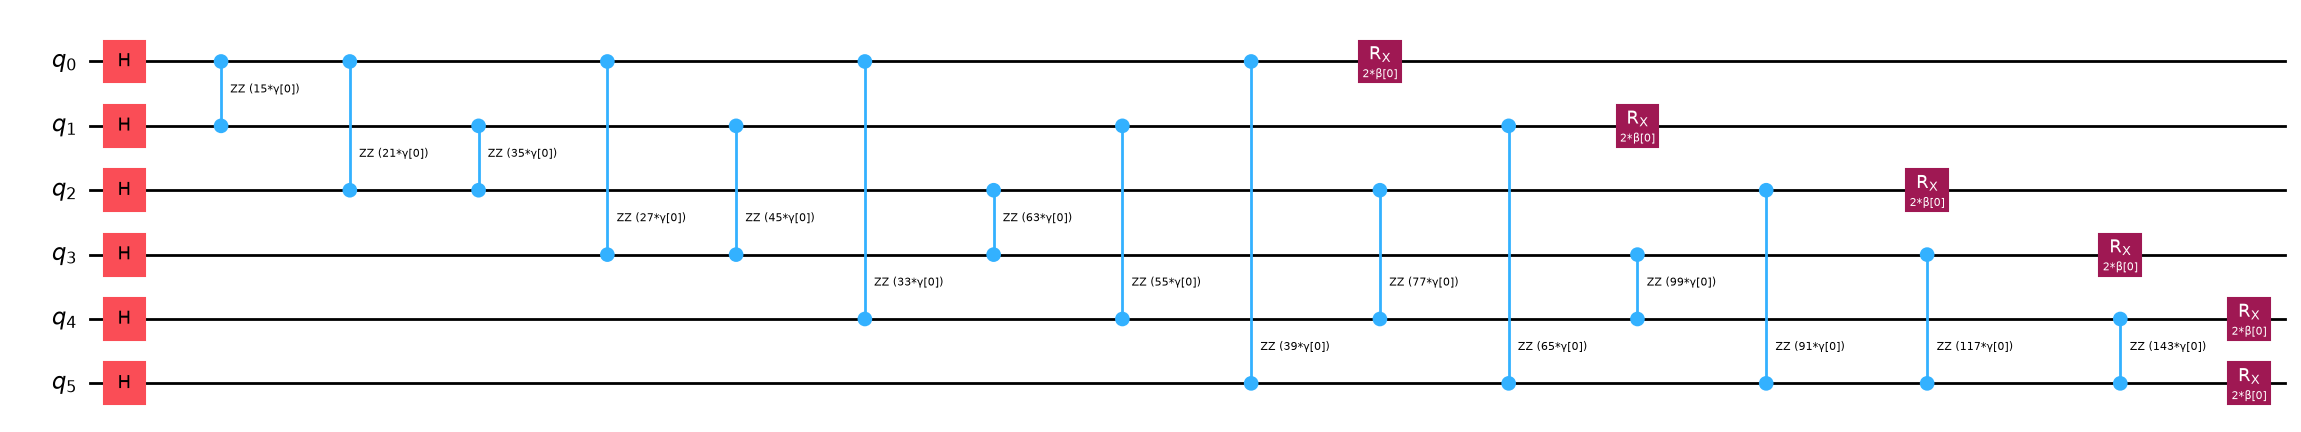

In [13]:
# Create pass manager for transpilation
pm = generate_preset_pass_manager(
    optimization_level=3, backend=backend, seed_transpiler=seed
)
edge_coloring = nx.greedy_color(
    nx.line_graph(partition_graph), strategy="saturation_largest_first"
)
edge_coloring.update({(k[1], k[0]): v for k, v in edge_coloring.items()})

num_colors = len(set(edge_coloring.values()))


# Make an empty swap strategy as we have a hardware-native graph here
cmap = CouplingMap(partition_graph.edges())
cmap.make_symmetric()

swap_strategy = SwapStrategy(cmap, ())  # no SWAPs needed

staged_pm = generate_preset_qaoa_pass_manager(
    backend, swap_strategy, initial_layout=None, edge_coloring=edge_coloring
)
# pm = staged_pm
candidate_circuit = pm.run(UnrollBoxes()(circuit))
candidate_circuit_sampler = pm.run(UnrollBoxes()(circuit_sampler))
candidate_circuit.draw("mpl", fold=False, idle_wires=False)

Now, we run the QAOA algorithm. You can either use the pre-trained parameters directly as an approximate solution by setting `training=False`, to skip the optimization step, or use them as an initial guess by passing them via `init_params` and setting `training=True`, allowing you to further optimize them and evaluate how much you can improve the results.

If you are not familiar with optimization loops in [Variational Quantum Algorithms](https://quantum.cloud.ibm.com/learning/courses/variational-algorithm-design/variational-algorithms) we recommend reviewing [this course](https://quantum.cloud.ibm.com/learning/courses/variational-algorithm-design/optimization-loops). For a more in-depth approach, you can also explore [this tutorial](https://quantum.cloud.ibm.com/docs/tutorials/quantum-approximate-optimization-algorithm) to see these concepts applied in a QAOA scenario.

In [14]:
training = False
init_params = np.load("utils/pretrained_parameters_small.npy")

In [15]:
objective_func_vals = []  # Global variable


def cost_func_estimator(params, ansatz, hamiltonian, estimator):

    # transform the observable defined on virtual qubits to
    # an observable defined on all physical qubits
    isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

    pub = (ansatz, isa_hamiltonian, params)
    job = estimator.run([pub])

    results = job.result()[0]
    cost = results.data.evs

    objective_func_vals.append(cost)

    return cost


max_iter = 30

if training:
    # Try with Session session, fallback to Job mode if it fails
    try:
        session = Session(backend=backend)
        estimator = Estimator(mode=session)
        use_session = True
        print("We are using Session mode")
    except:
        estimator = Estimator(mode=backend)
        use_session = False
        print("We are using Job mode")

    estimator.options.default_shots = 10000
    estimator.options.environment.job_tags = ["fallfest26-warsaw"]

    if use_session:
        with session:
            result = minimize(
                cost_func_estimator,
                init_params,
                args=(candidate_circuit, partition_hamiltonian, estimator),
                method="COBYLA",
                options={"maxiter": max_iter, "tol": 1e-8, "rhobeg": 0.001},
            )
    else:
        result = minimize(
            cost_func_estimator,
            init_params,
            args=(candidate_circuit, partition_hamiltonian, estimator),
            method="COBYLA",
            options={"maxiter": max_iter, "tol": 1e-8, "rhobeg": 0.001},
        )

    optimized_params = result.x
    np.save("optimized_parameters_small_custom.npy", optimized_params)
    plt.figure(figsize=(12, 6))
    plt.plot(objective_func_vals, lw=0.75, marker=".")
    plt.xlabel("Iteration")
    plt.ylabel("Cost")
    plt.show()


else:
    optimized_params = np.load("utils/pretrained_parameters_small.npy")
optimized_circuit = candidate_circuit_sampler.assign_parameters(optimized_params)

# 2. Applying different Error Mitigation and Suppression techniques to the Sampler

Now we are going to apply different [error mitigation and suppression techniques](https://quantum.cloud.ibm.com/docs/guides/error-mitigation-and-suppression-techniques) to try to get the best results for the partition problem. This will complement the techniques you learned in Lab 3 from a more practical perspective - in particular, in a quantum optimization setting. 

<a id="exercise_2"></a>
<div class="alert alert-block alert-success">
    
<b>Exercise 2: Use the Sampler with different levels of Error Mitigation techniques</b>

**Your Goal:** Apply different error mitigation techniques to the quantum circuit execution and compare the results.

Test the following four configurations using 1000 shots:

- **2a: No Error Mitigation or Suppression** (baseline)  
  Raw hardware results without any error mitigation or suppression techniques

- **2b: Error Suppression + Twirling**  
  Dynamical Decoupling + Pauli Twirling (gates and measure) to suppress coherent errors during circuit execution

- **2c: M3 Error Mitigation Only**  
  Matrix-free Measurement Mitigation to correct readout errors in post-processing

- **2d: M3 Error Mitigation + Error Suppression + Twirling** (full stack)  
  Combined approach using both suppression during execution and mitigation in post-processing

Compare the accuracy and performance of each approach to understand the impact of different error mitigation strategies.

</div>

First we will define the [`SamplerOptions`](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/options-sampler-options) object for each case and then we will run the workflows.

In [16]:
# =============================================================================
# VERSION 1: No Error Mitigation or Suppression
# =============================================================================
print("=" * 80)
print("VERSION 1: No Error Mitigation or Suppression")
print("=" * 80)

options_v1 = SamplerOptions()
# ---- TODO : Task 2a --- (filled, Track 1 build)
# Set the number of shots to 1000 and define the SamplerOptions for the quantum circuit execution
shots = 1000
options_v1.default_shots = shots
# ---- end of TODO : Task 2a ---

VERSION 1: No Error Mitigation or Suppression


In [ ]:
## Verify your answer ##
# Original call:
# grade_lab4a_ex2a(options_v1)
print("SKIPPED (local phase): grade_lab4a_ex2a — run in David's session")


SKIPPED (local phase): grade_lab4a_ex2a — run in David's session


Now apply [Dynamical Decoupling](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/options-dynamical-decoupling-options) and [Pauli Twirling](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/options-twirling-options) (gates and measure twirling). 

In [18]:
# =============================================================================
# VERSION 2: Error Suppression Only (Dynamical Decoupling + Twirling)
# =============================================================================
print("=" * 80)
print("VERSION 2: Error Suppression Only")
print("=" * 80)


options_v2 = SamplerOptions()
# ---- TODO : Task 2b ---
# Configure error suppression options
options_v2.default_shots = shots
# Set dynamical decoupling to reduce decoherence errors
options_v2.dynamical_decoupling.enable = True
options_v2.dynamical_decoupling.sequence_type = "XX"
# Enable gate twirling to randomize coherent errors
options_v2.twirling.enable_gates = True
# Enable measurement twirling to randomize readout errors
options_v2.twirling.enable_measure = True
options_v2.twirling.num_randomizations = 32
# NOTE (local phase): these are IBM Runtime options; they take effect on
# David's hardware run. The local Aer run of VERSION 2 (below) executes the
# same circuit without them — on an ideal simulator they are no-ops.

# ---- end of TODO : Task 2b ---

VERSION 2: Error Suppression Only


In [ ]:
## Verify your answer ##
# Original call:
# grade_lab4a_ex2b(options_v2)
print("SKIPPED (local phase): grade_lab4a_ex2b — run in David's session")


SKIPPED (local phase): grade_lab4a_ex2b — run in David's session


Now that you have succesfully completed Ex2a and Ex2b, we will run those workflows to use the results to be further post-processed by the M3 technique.

*Usage estimate: 5 seconds on a Heron r2 processor (NOTE: This is an estimate only. Your runtime might vary.)*

*The usage estimate reflects only backend execution. Cell runtime can still take minutes due to queueing, calibration, and session delays. You can check the status of your job in [IBM Quantum Platform](https://quantum.cloud.ibm.com/).*

In [ ]:
# =============================================================================
# VERSION 1: No Error Mitigation or Suppression
# =============================================================================
# ── LOCAL ADAPTATION ── IBM Runtime Sampler -> qiskit-aer SamplerV2 on the
# ideal simulator. (SamplerOptions/job_tags are Runtime-only; the options
# objects above are still built and graded in simulator session.)
from qiskit_aer.primitives import SamplerV2 as AerSamplerV2

sampler_v1 = AerSamplerV2()

pub_v1 = (optimized_circuit,)
job_v1 = sampler_v1.run([pub_v1], shots=shots)
print("Job ID of job_v1:", job_v1.job_id())
counts_bin_v1 = job_v1.result()[0].data.meas.get_counts()

final_distribution_bin_v1 = {key: val / shots for key, val in counts_bin_v1.items()}

final_distribution_bin_v1 = dict(
    sorted(final_distribution_bin_v1.items(), key=lambda item: item[1], reverse=True)
)
print("Results (no mitigation):")
print(final_distribution_bin_v1)


Job ID of job_v1: 44c7e65d-72f0-4772-8c4d-3c219ed487f6
Results (no mitigation):
{'001111': 0.034, '001011': 0.032, '001101': 0.031, '011001': 0.031, '100111': 0.03, '011100': 0.029, '100101': 0.029, '011010': 0.029, '001110': 0.028, '101000': 0.027, '010101': 0.027, '010110': 0.027, '011011': 0.026, '100110': 0.026, '100011': 0.025, '101001': 0.025, '101011': 0.025, '101100': 0.024, '101010': 0.024, '110000': 0.024, '010100': 0.023, '110100': 0.022, '011000': 0.022, '110001': 0.022, '010011': 0.02, '001100': 0.018, '100010': 0.018, '101101': 0.017, '110010': 0.017, '000111': 0.017, '111000': 0.016, '100100': 0.016, '101110': 0.016, '011101': 0.015, '010111': 0.015, '010010': 0.014, '110011': 0.014, '001010': 0.013, '110101': 0.011, '011110': 0.011, '100001': 0.011, '111001': 0.01, '111010': 0.008, '011111': 0.007, '000010': 0.007, '110110': 0.007, '000110': 0.006, '010001': 0.006, '111111': 0.005, '000100': 0.004, '000101': 0.004, '010000': 0.004, '000001': 0.004, '001000': 0.004, '111

**Troubleshooting: Retrieving Lost Jobs**

If you lose access to your job variables due to a kernel restart or session interruption, you can still retrieve your results without rerunning the job on hardware. This saves valuable QPU time. Execute the cell below to retrieve a job using its job ID.

If you do not have the job ID readily available, you can find it in [IBM Quantum Platform](https://quantum.cloud.ibm.com/) by checking your job history under the Jobs tab.

In [21]:
# ── LOCAL ADAPTATION ── service.job(<id>) retrieval needs the Runtime
# service (David's session). Locally the Aer job object is already in hand.
job_id_v1 = job_v1.job_id()
print("Local Aer job_v1 id:", job_id_v1)


Local Aer job_v1 id: 44c7e65d-72f0-4772-8c4d-3c219ed487f6


*Usage estimate: 5 seconds on a Heron r2 processor (NOTE: This is an estimate only. Your runtime might vary.)*

*The usage estimate reflects only backend execution. Cell runtime can still take minutes due to queueing, calibration, and session delays. You can check the status of your job in [IBM Quantum Platform](https://quantum.cloud.ibm.com/).*

In [ ]:
# =============================================================================
# VERSION 2: Error Suppression Only (Dynamical Decoupling + Twirling)
# =============================================================================
# ── LOCAL ADAPTATION ── Aer run of the same circuit. DD/twirling are IBM
# Runtime execution options and cannot act on an ideal simulator, so locally
# VERSION 2 samples the same distribution as VERSION 1 (up to shot noise).
# The suppression comparison is a hardware result (USER's session).

sampler_v2 = AerSamplerV2()

## Use Hardware: (comment out above sampler_v2 declaration)
# from qiskit_ibm_runtime import SamplerV2 as Sampler
# sampler_v2 = Sampler(mode=backend, options=options_v1)

pub_v2 = (optimized_circuit,)
job_v2 = sampler_v2.run([pub_v2], shots=shots)
print("Job ID of job_v2:", job_v2.job_id())
counts_bin_v2 = job_v2.result()[0].data.meas.get_counts()
final_distribution_bin_v2 = {key: val / shots for key, val in counts_bin_v2.items()}
final_distribution_bin_v2 = dict(
    sorted(final_distribution_bin_v2.items(), key=lambda item: item[1], reverse=True)
)
print("Results (error suppression only):")
print(final_distribution_bin_v2)
print()


Job ID of job_v2: 1f1ac7b0-1332-4d61-92bc-a6c139dbc9a9
Results (error suppression only):
{'001111': 0.033, '100101': 0.032, '110010': 0.031, '110001': 0.03, '001011': 0.03, '011000': 0.03, '011001': 0.028, '001110': 0.028, '100011': 0.027, '011100': 0.027, '100110': 0.027, '101100': 0.026, '101001': 0.026, '010101': 0.026, '010110': 0.025, '110000': 0.024, '010111': 0.024, '100111': 0.023, '101010': 0.023, '001100': 0.023, '110100': 0.023, '011011': 0.023, '010011': 0.022, '010100': 0.022, '011010': 0.021, '100010': 0.019, '111000': 0.018, '101101': 0.017, '110101': 0.017, '001101': 0.017, '000111': 0.017, '101000': 0.015, '011101': 0.015, '100100': 0.013, '001010': 0.013, '110011': 0.013, '101011': 0.013, '011110': 0.013, '000101': 0.01, '101110': 0.01, '100001': 0.01, '010010': 0.01, '000110': 0.009, '000011': 0.008, '111001': 0.008, '110110': 0.008, '100000': 0.008, '011111': 0.008, '010001': 0.007, '111100': 0.007, '001001': 0.005, '000100': 0.004, '010000': 0.004, '111010': 0.004,

After running these two workflows, we can use the obtained counts to be analyzed by M3.

The M3 ([Matrix‑free Measurement Mitigation](https://qiskit.github.io/qiskit-addon-mthree/)) method is a scalable approach to readout error mitigation that avoids constructing the full $2^n \times 2^n$ assignment matrix by using simplified models of readout errors. It assumes that correlations of order three and higher are negligible, which allows it to rely only on single-qubit and two-qubit assignment matrices obtained by preparing all qubits in the $\lvert 0\ldots0\rangle$ and $\lvert 1\ldots1\rangle$ states and measuring their error rates. These small $2\times2$ and $4\times4$ matrices are stored and later combined to form an effective mitigation matrix that is built only from the bitstrings observed during sampling. Because the size of this effective matrix grows with the number of sampled outcomes rather than $2^n$, M3 can be applied to circuits with much longer bitstrings than traditional linear algebra methods.

Now you are asked to use it to reduce the error in the sampling of the quantum circuit. See this [tutorial](https://quantum.cloud.ibm.com/docs/tutorials/readout-error-mitigation-sampler) for a more in-depth analysis. Also, if you want a more hands-on approach to see which functions you need to apply, see [this tutorial](https://qiskit.github.io/qiskit-addon-mthree/tutorials/01_M3_ex1.html).

*Usage estimate: 7 seconds on a Heron r2 processor (NOTE: This is an estimate only. Your runtime might vary.)*

*The usage estimate reflects only backend execution. Cell runtime can still take minutes due to queueing, calibration, and session delays. You can check the status of your job in [IBM Quantum Platform](https://quantum.cloud.ibm.com/).*

In [23]:
# =============================================================================
# VERSION 3: M3 Error Mitigation Only
# =============================================================================
print("=" * 80)
print("VERSION 3: M3 Error Mitigation Only")
print("=" * 80)

# We copy the setup from version 1, but focus only on M3 mitigation
options_v3 = options_v1
counts_bin_v3 = counts_bin_v1
job_v3 = job_v1
# ---- TODO : Task 2c ---
# Get the physical qubit mapping from the optimized circuit using the mthree.utils.final_measurement_mapping function

meas_map_v3 = mthree.utils.final_measurement_mapping(optimized_circuit)

# Build mitigator using mthree.M3Mitigation (locally: the Aer backend)
mit_v3 = mthree.M3Mitigation(backend)

# Calibrate the mitigator using the .cals_from_system method and the meas_map_v3
mit_v3.cals_from_system(meas_map_v3)

# Use the .apply_correction method on counts_bin_v3 to returns quasi-probabilities
m3_quasis_v3 = mit_v3.apply_correction(counts_bin_v3, meas_map_v3)
# NOTE (local phase): Aer is noiseless, so calibration matrices are ~identity
# and M3 changes nothing beyond rounding — the mitigation effect is a
# hardware result (David's session).
# ---- end of TODO : Task 2c ---

def convert_bin_list(dist, shots=10000):
    # Step 1: convert to (non-negative) counts
    counts = {
        k: (int(round(float(v) * shots)) if float(v) >= 0 else 0)
        for k, v in dist.items()
    }
    # Step 2: normalize
    total_counts = sum(counts.values())
    return {k: round(v / total_counts, int(np.log10(shots))) for k, v in counts.items()}


final_distribution_bin_v3 = convert_bin_list(dict(m3_quasis_v3), shots=shots)
final_distribution_bin_v3 = dict(
    sorted(final_distribution_bin_v3.items(), key=lambda item: item[1], reverse=True)
)
print("Results (M3 mitigation only):")
print(final_distribution_bin_v3)
print()

VERSION 3: M3 Error Mitigation Only
Results (M3 mitigation only):
{'001111': 0.034, '001011': 0.032, '001101': 0.031, '011001': 0.031, '100111': 0.03, '011010': 0.029, '011100': 0.029, '100101': 0.029, '001110': 0.028, '010101': 0.027, '010110': 0.027, '101000': 0.027, '011011': 0.026, '100110': 0.026, '100011': 0.025, '101001': 0.025, '101011': 0.025, '101010': 0.024, '101100': 0.024, '110000': 0.024, '010100': 0.023, '011000': 0.022, '110001': 0.022, '110100': 0.022, '010011': 0.02, '001100': 0.018, '100010': 0.018, '000111': 0.017, '101101': 0.017, '110010': 0.017, '100100': 0.016, '101110': 0.016, '111000': 0.016, '010111': 0.015, '011101': 0.015, '010010': 0.014, '110011': 0.014, '001010': 0.013, '011110': 0.011, '100001': 0.011, '110101': 0.011, '111001': 0.01, '111010': 0.008, '000010': 0.007, '011111': 0.007, '110110': 0.007, '000110': 0.006, '010001': 0.006, '111111': 0.005, '000001': 0.004, '000100': 0.004, '000101': 0.004, '001000': 0.004, '010000': 0.004, '111101': 0.004, '

In [ ]:
## Verify your answer ##
# Original call:
# grade_lab4a_ex2c(m3_quasis_v3)
print("SKIPPED (local phase): grade_lab4a_ex2c — run in David's session")


SKIPPED (local phase): grade_lab4a_ex2c — run in David's session


*Usage estimate: 7 seconds on a Heron r2 processor (NOTE: This is an estimate only. Your runtime might vary.)*

*The usage estimate reflects only backend execution. Cell runtime can still take minutes due to queueing, calibration, and session delays. You can check the status of your job in [IBM Quantum Platform](https://quantum.cloud.ibm.com/).*

In [25]:
# =============================================================================
# VERSION 4: M3 Error Mitigation + Error Suppression
# =============================================================================
print("=" * 80)
print("VERSION 4: M3 Error Mitigation + Error Suppression")
print("=" * 80)

options_v4 = options_v2
counts_bin_v4 = counts_bin_v2
job_v4 = job_v2
# ---- TODO : Task 2d ---
# Apply M3 correction on top of error suppression
# Get the physical qubit mapping from the optimized circuit using the mthree.utils.final_measurement_mapping function

meas_map_v4 = mthree.utils.final_measurement_mapping(optimized_circuit)

# Build mitigator using mthree.M3Mitigation (locally: the Aer backend)
mit_v4 = mthree.M3Mitigation(backend)

# Calibrate the mitigator using the .cals_from_system method and the meas_map_v4
mit_v4.cals_from_system(meas_map_v4)

# Use the .apply_correction method on counts_bin_v4 to returns quasi-probabilities
m3_quasis_v4 = mit_v4.apply_correction(counts_bin_v4, meas_map_v4)

# ---- End of TODO : Task 2d ---
final_distribution_bin_v4 = convert_bin_list(dict(m3_quasis_v4), shots=shots)
final_distribution_bin_v4 = dict(
    sorted(final_distribution_bin_v4.items(), key=lambda item: item[1], reverse=True)
)
print("Results (M3 mitigation + error suppression):")
print(final_distribution_bin_v4)
print()

VERSION 4: M3 Error Mitigation + Error Suppression


Results (M3 mitigation + error suppression):
{'001111': 0.033, '100101': 0.032, '110010': 0.031, '001011': 0.03, '011000': 0.03, '110001': 0.03, '001110': 0.028, '011001': 0.028, '011100': 0.027, '100011': 0.027, '100110': 0.027, '010101': 0.026, '101001': 0.026, '101100': 0.026, '010110': 0.025, '010111': 0.024, '110000': 0.024, '001100': 0.023, '011011': 0.023, '100111': 0.023, '101010': 0.023, '110100': 0.023, '010011': 0.022, '010100': 0.022, '011010': 0.021, '100010': 0.019, '111000': 0.018, '000111': 0.017, '001101': 0.017, '101101': 0.017, '110101': 0.017, '011101': 0.015, '101000': 0.015, '001010': 0.013, '011110': 0.013, '100100': 0.013, '101011': 0.013, '110011': 0.013, '000101': 0.01, '010010': 0.01, '100001': 0.01, '101110': 0.01, '000110': 0.009, '000011': 0.008, '011111': 0.008, '100000': 0.008, '110110': 0.008, '111001': 0.008, '010001': 0.007, '111100': 0.007, '001001': 0.005, '000000': 0.004, '000100': 0.004, '010000': 0.004, '101111': 0.004, '111010': 0.004, '000010':

In [ ]:
## Verify your answer ##
# Original call:
# grade_lab4a_ex2d(m3_quasis_v4)
print("SKIPPED (local phase): grade_lab4a_ex2d — run in David's session")


SKIPPED (local phase): grade_lab4a_ex2d — run in David's session


In [27]:
# =============================================================================
# Summary Comparison
# =============================================================================
print("=" * 80)
print("SUMMARY")
print("=" * 80)
print("V1 (No mitigation):              ", list(final_distribution_bin_v1.items())[:3])
print("V2 (Suppression only):           ", list(final_distribution_bin_v2.items())[:3])
print("V3 (M3 only):                    ", list(final_distribution_bin_v3.items())[:3])
print("V4 (M3 + Suppression):           ", list(final_distribution_bin_v4.items())[:3])

SUMMARY
V1 (No mitigation):               [('001111', 0.034), ('001011', 0.032), ('001101', 0.031)]
V2 (Suppression only):            [('001111', 0.033), ('100101', 0.032), ('110010', 0.031)]
V3 (M3 only):                     [('001111', 0.034), ('001011', 0.032), ('001101', 0.031)]
V4 (M3 + Suppression):            [('001111', 0.033), ('100101', 0.032), ('110010', 0.031)]


In [28]:
bitstring_v1, set1_v1, set2_v1, difference_v1, v1 = analyze_partition_result(
    final_distribution_bin_v1, numbers, partition_graph, "VERSION 1: No Mitigation"
)
bitstring_v2, set_v2, set2_v2, difference_v2, v2 = analyze_partition_result(
    final_distribution_bin_v2,
    numbers,
    partition_graph,
    "VERSION 2: Error Suppression Only",
)
bitstring_v3, set1_v3, set2_v3, difference_v3, v3 = analyze_partition_result(
    final_distribution_bin_v3, numbers, partition_graph, "VERSION 3: M3 Mitigation Only"
)
bitstring_v4, set1_v4, set2_v4, difference_v4, v4 = analyze_partition_result(
    final_distribution_bin_v4,
    numbers,
    partition_graph,
    "VERSION 4: M3 + Error Suppression",
)


Analysis for VERSION 1: No Mitigation
Result bitstring: [1, 1, 1, 1, 0, 0]

QAOA Partition Result:
Set 1: [3, 5, 7, 9] (sum = 24)
Set 2: [11, 13] (sum = 24)
Difference: 0

Analysis for VERSION 2: Error Suppression Only
Result bitstring: [1, 1, 1, 1, 0, 0]

QAOA Partition Result:
Set 1: [3, 5, 7, 9] (sum = 24)
Set 2: [11, 13] (sum = 24)
Difference: 0

Analysis for VERSION 3: M3 Mitigation Only
Result bitstring: [1, 1, 1, 1, 0, 0]

QAOA Partition Result:
Set 1: [3, 5, 7, 9] (sum = 24)
Set 2: [11, 13] (sum = 24)
Difference: 0

Analysis for VERSION 4: M3 + Error Suppression
Result bitstring: [1, 1, 1, 1, 0, 0]

QAOA Partition Result:
Set 1: [3, 5, 7, 9] (sum = 24)
Set 2: [11, 13] (sum = 24)
Difference: 0


In [29]:
# Collect results in a structured way
results_sampler = {
    "v1": {
        "bitstring": bitstring_v1,
        "set1": set1_v1,
        "set2": set2_v1,
        "difference": difference_v1,
        "label": "VERSION 1: No Mitigation",
    },
    "v2": {
        "bitstring": bitstring_v2,
        "set1": set_v2,
        "set2": set2_v2,
        "difference": difference_v2,
        "label": "VERSION 2: Error Suppression Only",
    },
    "v3": {
        "bitstring": bitstring_v3,
        "set1": set1_v3,
        "set2": set2_v3,
        "difference": difference_v3,
        "label": "VERSION 3: M3 Mitigation Only",
    },
    "v4": {
        "bitstring": bitstring_v4,
        "set1": set1_v4,
        "set2": set2_v4,
        "difference": difference_v4,
        "label": "VERSION 4: M3 + Error Suppression",
    },
}

# Select the version with the smallest difference
best_key, best_result = min(
    reversed(list(results_sampler.items())), key=lambda item: item[1]["difference"]
)

# Print summary
print("\n✅ Best result:")
print(f"Method     : {best_key} ({best_result['label']})")
print(f"Bitstring  : {best_result['bitstring']}")
print(f"Set 1      : {best_result['set1']}")
print(f"Set 2      : {best_result['set2']}")
print(f"Difference : {best_result['difference']}")


✅ Best result:
Method     : v4 (VERSION 4: M3 + Error Suppression)
Bitstring  : [1, 1, 1, 1, 0, 0]
Set 1      : [3, 5, 7, 9]
Set 2      : [11, 13]
Difference : 0


Now we are going to check that you have correctly executed all the jobs using the `SamplerOptions` you defined above.

In [30]:
options_list = [options_v1, options_v2, options_v3, options_v4]
probs_list = [
    final_distribution_bin_v1,
    final_distribution_bin_v2,
    final_distribution_bin_v3,
    final_distribution_bin_v4,
]
job_list = [job_v1, job_v2, job_v3, job_v4]

In [ ]:
## Verify your answer ##
# Original call:
# grade_lab4a_ex2(results_sampler, options_list)
print("SKIPPED (local phase): grade_lab4a_ex2 — run in David's session")


SKIPPED (local phase): grade_lab4a_ex2 — run in David's session


## 3. Scaling to Larger Problems: Pauli Correlation Encoding

Now let's tackle a more complicated graph of 160 nodes. To handle such large problems on current quantum hardware with limited qubits, we need to reduce the number of qubits required. 

**Pauli Correlation Encoding** is a technique for encoding multiple classical variables using fewer qubits by exploiting correlations in the problem structure. Instead of using one qubit per node, we encode node states in the correlations between pairs of qubits. The figure below provides a visual illustration of how this encoding works.

<div style="text-align:center;">
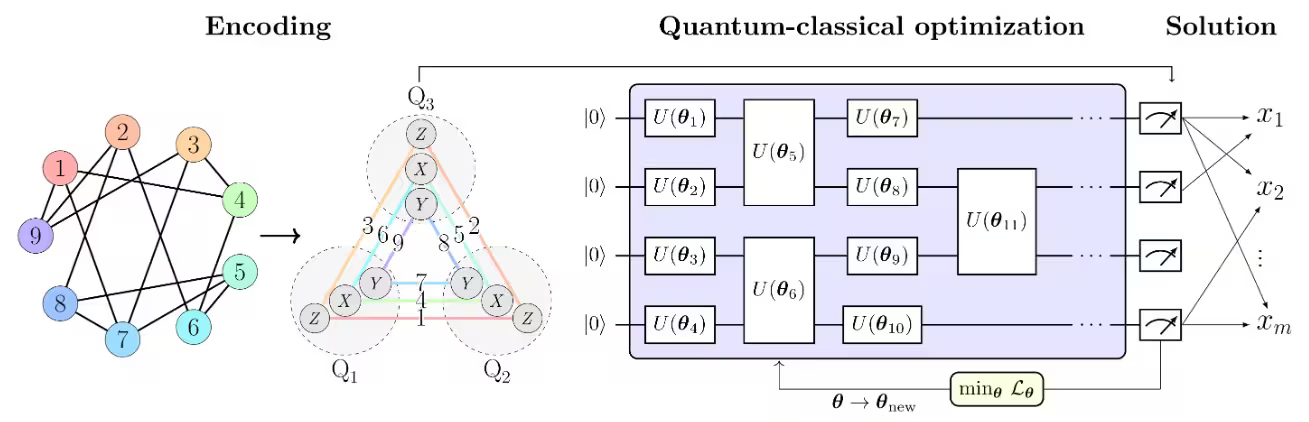
</div>

For more details, refer to [the Pauli Correlation Encoding tutorial](https://quantum.cloud.ibm.com/docs/tutorials/pauli-correlation-encoding-for-qaoa) based on [Sciorili et al.](https://www.nature.com/articles/s41467-024-55346-z).

In [32]:
n = 160
# We pre-generated 160 random integers in [0, 100] using np.random.randint(0, 100, size=n)
# For reproducibility, we load this pre-generated numbers here
numbers_large = np.load("utils/numbers_large.npy")

print(f"Numbers to partition: {numbers_large}")
print(f"Total sum: {sum(numbers_large)}")

partition_graph_large = build_partition_graph(numbers_large)

print(
    f"\nGraph created with {len(partition_graph_large.nodes())} nodes and {len(partition_graph_large.edges())} edges"
)

Numbers to partition: [51 92 14 71 60 20 82 86 74 74 87 99 23  2 21 52  1 87 29 37  1 63 59 20
 32 75 57 21 88 48 90 58 41 91 59 79 14 61 61 46 61 50 54 63  2 50  6 20
 72 38 17  3 88 59 13  8 89 52  1 83 91 59 70 43  7 46 34 77 80 35 49  3
  1  5 53  3 53 92 62 17 89 43 33 73 61 99 13 94 47 14 71 77 86 61 39 84
 79 81 52 23 25 88 59 40 28 14 44 64 88 70  8 87  0  7 87 62 10 80  7 34
 34 32  4 40 27  6 72 71 11 33 32 47 22 61 87 36 98 43 85 90 34 64 98 46
 77  2  0  4 89 13 26  8 78 14 89 41 76 50 62 95]
Total sum: 7853

Graph created with 160 nodes and 12720 edges


Following what is done in [this tutorial](https://quantum.cloud.ibm.com/docs/tutorials/pauli-correlation-encoding-for-qaoa) and in [this paper](https://www.nature.com/articles/s41467-024-55346-z), we can reduce the number of qubits by order $\mathcal{O}(\sqrt{n})$.

<a id="exercise_3a"></a>
<div class="alert alert-block alert-success">
    
<b>Exercise 3a: Implement Pauli Correlation Encoding: Qubit reduction </b> 

**Your Goal:** Reduce the number of qubits from $n$ to $\mathcal{O}(\sqrt{n})$ by using Pauli Correlation Encoding. Check out the paper or the tutorial for the specific formula. 

Also, define the lists `node_x`, `node_y`, and `node_z` to specify which nodes are encoded using Pauli X, Y, and Z operators.



</div>

In [33]:
# ---- TODO : Task 3a ---
def reduce_qubits_with_pce(initial_qubits: int) -> int:
    """
    Reduce the number of qubits from n to O(sqrt(n)) using Pauli Correlation Encoding.
    
    Parameters
    ----------
    initial_qubits : int
        The original number of qubits before encoding.
    
    Returns
    -------
    int
        The reduced number of qubits after applying PCE.
    Examples
        --------
        >>> reduce_qubits_with_pce(160)
        11
    """
    # Smallest m whose X/Y/Z pairwise correlations cover n variables:
    # 3 * C(m, 2) >= n.  For n = 160: m = 11 (3 * 55 = 165 >= 160).
    final_qubits = 1
    while 3 * final_qubits * (final_qubits - 1) // 2 < initial_qubits:
        final_qubits += 1
    return final_qubits



# Split the n variables across the three Pauli settings (X, Y, Z).
list_size = -(-n // 3)  # ceil(n / 3) = 54 for n = 160
node_x = list(range(0, list_size))
node_y = list(range(list_size, 2 * list_size))
node_z = list(range(2 * list_size, n))

# ---- TODO : Task 3a ---
num_qubits = reduce_qubits_with_pce(n)
print(f"Number of qubits: {num_qubits}")
print("List 1:", node_x)
print("List 2:", node_y)
print("List 3:", node_z)

Number of qubits: 11
List 1: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]
List 2: [54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107]
List 3: [108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159]


In [ ]:
## Verify your answer ##
# Original call:
# grade_lab4a_ex3a(num_qubits, node_x, node_y, node_z)
print("SKIPPED (local phase): grade_lab4a_ex3a — run in David's session")


SKIPPED (local phase): grade_lab4a_ex3a — run in David's session


<a id="exercise_3b"></a>
<div class="alert alert-block alert-success">
    
<b>Exercise 3b: Implement Pauli Correlation Encoding: Hamiltonian construction </b> 

**Your Goal:** Implement <code>build_pauli_correlation_encoding</code> to generate 2-body Pauli correlation Hamiltonian terms.
Use the lists <code>node_x</code>, <code>node_y</code>, and <code>node_z</code> to control how logical nodes are encoded using Pauli X, Y, and Z operators.




</div>

In [35]:
def build_pauli_correlation_encoding(pauli: str, node_list: list, n: int, k=2) -> list:
    """
    Build a list of Pauli Hamiltonian terms encoding k-body correlations
    for a given Pauli operator.

    This function constructs Pauli strings acting with the given `pauli`
    operator on all k-combinations of qubits (up to the size of `node_list`)
    and returns them as SparsePauliOp Hamiltonian terms with unit weight.

    Parameters
    ----------
    pauli : str
        Single-qubit Pauli operator ("X", "Y", or "Z").
    node_list : list
        List of nodes (or indices) used to limit the number of correlations.
    n : int
        Total number of qubits.
    k : int, optional
        Order of correlation (default is 2 for pairwise correlations).

    Returns
    -------
    hamiltonian : list of SparsePauliOp
        List of Hamiltonian terms encoding the Pauli correlations.
    """
    # ---- TODO : Task 3b --- (filled, Track 1 build)
    # One unit-weight term per entry of node_list, taken in order from the
    # k-combinations of qubit indices: term j encodes variable node_list[j]
    # as the correlation <P_i P_j> over the j-th qubit pair.
    hamiltonian = []
    pairs = list(combinations(range(n), k))[: len(node_list)]
    for i, j in pairs:
        label = ["I"] * n
        label[i] = pauli
        label[j] = pauli
        # SparsePauliOp labels are little-endian (rightmost char = qubit 0)
        hamiltonian.append(SparsePauliOp("".join(reversed(label)), coeffs=[1.0]))
    # ---- END of TODO : Task 3b ---
    return hamiltonian


pauli_correlation_encoding_x = build_pauli_correlation_encoding("X", node_x, num_qubits)
pauli_correlation_encoding_y = build_pauli_correlation_encoding("Y", node_y, num_qubits)
pauli_correlation_encoding_z = build_pauli_correlation_encoding("Z", node_z, num_qubits)

In [ ]:
## Verify your answer ##
# Original call:
# grade_lab4a_ex3b(pauli_correlation_encoding_x, pauli_correlation_encoding_y, pauli_correlation_encoding_z)
print("SKIPPED (local phase): grade_lab4a_ex3b — run in David's session")


SKIPPED (local phase): grade_lab4a_ex3b — run in David's session


<a id="exercise_3c"></a>
<div class="alert alert-block alert-success">
    
<b>Exercise 3c: Implement Pauli Correlation Encoding: Cost Hamiltonian and QAOA ansatz </b> 

**Your Goal:** Combine the Pauli Correlation Encoding Hamiltonian terms into a single cost Hamiltonian (a SparsePauliOp object) and use it to construct the corresponding QAOA ansatz.


</div>

In [37]:
layers_large = 2
# ---- TODO : Task 3c --- (filled, Track 1 build)
# Cost operator for the ansatz: sum of all PCE correlation terms (X+Y+Z sets).
hamiltonian_pce = SparsePauliOp.sum(
    pauli_correlation_encoding_x
    + pauli_correlation_encoding_y
    + pauli_correlation_encoding_z
)
# reps=2 -> 4 parameters, matching utils/pretrained_parameters_pce.npy.
circuit_pce = annotated_qaoa_ansatz(hamiltonian_pce, reps=layers_large)

# ---- END of TODO : Task 3c ---

In [38]:
## Verify your answer ##
# ── DAVID'S SESSION ONLY ── grader calls require the authenticated qfest
# account (save_account) and fail from this VM (HTTP 403). Run in David's
# session after the hardware pass. Original call:
# grade_lab4a_ex3c(hamiltonian_pce, circuit_pce)
print("SKIPPED (local phase): grade_lab4a_ex3c — run in David's session")


SKIPPED (local phase): grade_lab4a_ex3c — run in David's session


Let's transpile the circuit:

In [39]:
edge_coloring = nx.greedy_color(
    nx.line_graph(partition_graph), strategy="saturation_largest_first"
)
edge_coloring.update({(k[1], k[0]): v for k, v in edge_coloring.items()})

num_colors = len(set(edge_coloring.values()))


cmap = CouplingMap(partition_graph.edges())
cmap.make_symmetric()
swap_strategy = SwapStrategy(cmap, ())
staged_pm = generate_preset_qaoa_pass_manager(
    backend, swap_strategy, initial_layout=None, edge_coloring=edge_coloring
)


pm = staged_pm

circuit_pce = pm.run(UnrollBoxes()(circuit_pce))

We define the loss function following the paper.

In [40]:
def loss_func_estimator(x, ansatz, hamiltonian, estimator, graph, experiment_result=[], job = None):
    """
    Calculates the specified loss function for the given ansatz, Hamiltonian, and graph.

    The expectation values of each Pauli string in the Hamiltonian are first obtained
    by running the ansatz on the quantum backend. These expectation values are then
    passed through the nonlinear function tanh(alpha * prod_i). The loss function is
    subsequently computed from these transformed values.
    """
    if job is None:
        job = estimator.run(
            [
                (ansatz, hamiltonian[0], x),
                (ansatz, hamiltonian[1], x),
                (ansatz, hamiltonian[2], x),
            ]
        )
        print("Creating new Job:", job.job_id())
    else:
        print("Using existing Job:", job.job_id())
    try:
        result = job.result()
    except:
        print(
            "Error: Unable to retrieve results from the job. "
            "Please verify that you are passing the correct job variable to the function."
        )
        return None, None, None

    # calculate the loss function
    node_exp_map = {}
    idx = 0
    for r in result:
        for ev in r.data.evs:
            node_exp_map[idx] = ev
            idx += 1

    loss = 0
    alpha = num_qubits
    for edge0, edge1, weight in graph.edges(data="weight"):
        loss += (
            weight
            * np.tanh(alpha * node_exp_map[edge0])
            * np.tanh(alpha * node_exp_map[edge1])
        )
    regulation_term = 0
    for i in range(len(graph.nodes())):
        regulation_term += np.tanh(alpha * node_exp_map[i]) ** 2
    regulation_term = regulation_term / len(graph.nodes())
    regulation_term = regulation_term**2
    beta = 1 / 2
    v = len(graph.edges()) / 2 + (len(graph.nodes()) - 1) / 4
    regulation_term = beta * v * regulation_term

    loss = loss + regulation_term

    print(f"Iter {len(experiment_result)}: {loss}")
    experiment_result.append(
        {"loss": loss, "exp_map": node_exp_map, "job_result": result}
    )
    return loss, experiment_result, job

In [41]:
# Build PCE operators with layout applied
# Note that here we need a list of 3 Hamiltonians, one for each Pauli term, instead of a single Hamiltonian such
pce = [
    [op.apply_layout(circuit_pce.layout) for op in pauli_correlation_encoding_x],
    [op.apply_layout(circuit_pce.layout) for op in pauli_correlation_encoding_y],
    [op.apply_layout(circuit_pce.layout) for op in pauli_correlation_encoding_z],
]


def run_pce_optimization(
    qc,
    backend,
    pce,
    partition_graph,
    loss_func_estimator,
    seed=seed,
    max_iter=30,
    training=False,
    filename="utils/pretrained_parameters_pce",
):

    counter = {"i": 0}
    last_x = {"value": None}
    last_fun = {"value": None}

    np.random.seed(seed)
    initial_params = 2 * np.pi * np.random.rand(qc.num_parameters)

    experiment_result = []

    if training:
        # Try with session, fallback to job if it fails
        try:
            session = Session(backend=backend)
            estimator = Estimator(mode=session)
            use_session = True
            print("We are using Session mode")
        except:
            estimator = Estimator(mode=backend)
            use_session = False
            print("We are using Job mode")

        estimator.options.default_shots = 10000
        estimator.options.environment.job_tags = ["fallfest26-warsaw"]

        def loss_func(x, experiment_result):
            last_x["value"] = x.copy()
            if counter["i"] + 1 > max_iter:
                return last_fun["value"]

            counter["i"] += 1

            val, experiment_result, _ = loss_func_estimator(
                x, qc, pce, estimator, partition_graph, experiment_result
            )

            last_fun["value"] = val
            return val

        if use_session:
            with session:
                result = minimize(
                    loss_func,
                    initial_params,
                    experiment_result,
                    method="COBYLA",
                    options={"maxiter": max_iter},
                )
        else:
            result = minimize(
                loss_func,
                initial_params,
                experiment_result,
                method="COBYLA",
                options={"maxiter": max_iter},
            )

        optimized_params = result.x
        np.save(filename, optimized_params)

    else:
        optimized_params = np.load(filename)

    return optimized_params, experiment_result


# You can use the pretrained parameters or run the optimization by setting `training=True`
optimized_params_pce, experiment_result_pce = run_pce_optimization(
    circuit_pce,
    backend,
    pce,
    partition_graph_large,
    loss_func_estimator,
    training=False,
    filename="utils/pretrained_parameters_pce.npy",
)


## 4. Error Mitigation Comparison for PCE-Expanded Partition Problem

Building on the PCE-scaled partition problem from Section 3, we now use the Estimator primitive to systematically compare different [error mitigation techniques](https://quantum.cloud.ibm.com/learning/courses/utility-scale-quantum-computing/error-mitigation) and identify the best possible cut, progressing from basic readout error mitigation to advanced probabilistic error cancellation and zero noise extrapolation. Check out [this tutorial](https://quantum.cloud.ibm.com/docs/tutorials/combine-error-mitigation-techniques) to see how these techniques work in practice.


<a id="exercise_4"></a>
<div class="alert alert-block alert-success">
    
<b>Exercise 4: Use the Estimator with different levels of Error Mitigation techniques</b>

**Your Goal:** Apply different error mitigation techniques to the quantum circuit execution using the Estimator primitive and compare the results.

Test the following four configurations with increasing sophistication:

- **4a: No Error Mitigation** (baseline)  
  Raw hardware results without any mitigation

- **4b: TREX (Twirled Readout Error eXtinction) + PT (Pauli Twirling on gates and measures)**  
  Mitigates measurement readout errors through randomized twirling

- **4c: ZNE (Zero Noise Extrapolation) + PT (Pauli Twirling on gates and measures)**  
  Extrapolates results to the zero-noise limit using multiple noise-scaled circuits

- **4d: PEC (Probabilistic Error Cancellation) + PT (Pauli Twirling on gates and measures)**  
  Uses quasi-probability decomposition to cancel gate errors probabilistically

Compare the accuracy, computational overhead, and performance of each approach to understand the trade-offs between different error mitigation strategies.

*Note that for each configuration, you must explicitly enable the desired techniques in `EstimatorOptions`. Just setting the resilience level will not be accepted by the grader.*
</div>

First we build the `EstimatorOptions` without any error mitigation or suppression technique, just defining the number of shots to 1000.

In [42]:
# No Error Mitigation (Resilience Level 0)
print("=" * 80)
print("Scenario 1: No Error Mitigation (Resilience Level 0)")
print("=" * 80)

est_options_no_em = EstimatorOptions()
# ---- TODO : Task 4a ---
# Configure estimator options without error mitigation and using your preferred number of shots
est_options_no_em.default_shots = 4096
# ---- END of TODO : Task 4a ---


Scenario 1: No Error Mitigation (Resilience Level 0)


In [ ]:
## Verify your answer ##
# Original call:
# grade_lab4a_ex4a(est_options_no_em)
print("SKIPPED (local phase): grade_lab4a_ex4a — run in David's session")


SKIPPED (local phase): grade_lab4a_ex4a — run in David's session


Now we build the EstimatorOptions using [Twirled Readout Error eXtinction (TREX)](https://quantum.cloud.ibm.com/docs/guides/error-mitigation-and-suppression-techniques#twirled-readout-error-extinction-trex), which reduces measurement errors by randomly flipping qubits before readout, and [Pauli Twirling](https://quantum.cloud.ibm.com/docs/guides/error-mitigation-and-suppression-techniques#pauli-twirling), which converts arbitrary noise channels into noise channels with more specific structure.

In [44]:
#  TREX (Twirled Readout Error eXtinction)
print("=" * 80)
print("Running with TREX (Twirled Readout Error eXtinction)")
print("=" * 80)
# ── LOCAL ADAPTATION ── the IBM Estimator is created in David's session;
# locally a qiskit-aer EstimatorV2 stands in (see the run cell below).
estimator_trex = None  # replaced by Aer EstimatorV2 at run time (local phase)
est_options_trex = EstimatorOptions()
# ---- TODO : Task 4b ---
# Configure estimator options with TREX (measurement error mitigation)
est_options_trex.default_shots = 4096
# Enable TREX - uses twirling to mitigate readout errors
est_options_trex.resilience.measure_mitigation = True
# Enable gate twirling (both gates and measure)
est_options_trex.twirling.enable_gates = True
est_options_trex.twirling.enable_measure = True

# ---- END of TODO : Task 4b ---

Running with TREX (Twirled Readout Error eXtinction)


In [ ]:
## Verify your answer ##
# Original call:
# grade_lab4a_ex4b(est_options_trex)
print("SKIPPED (local phase): grade_lab4a_ex4b — run in David's session")


SKIPPED (local phase): grade_lab4a_ex4b — run in David's session


Now we implement [Zero Noise Extrapolation (ZNE)](https://quantum.cloud.ibm.com/docs/guides/error-mitigation-and-suppression-techniques#zero-noise-extrapolation-zne), which intentionally amplifies circuit noise at different levels and extrapolates the results back to estimate the zero-noise limit, and [Pauli Twirling](https://quantum.cloud.ibm.com/docs/guides/error-mitigation-and-suppression-techniques#pauli-twirling).

In [46]:
# Scenario 3: ZNE (Zero Noise Extrapolation) + Gate Twirling
print("=" * 80)
print("Scenario 3: ZNE (Zero Noise Extrapolation) + Gate Twirling")
print("=" * 80)
estimator_zne = None  # replaced by Aer EstimatorV2 at run time (local phase)
est_options_zne = EstimatorOptions()
# ---- TODO : Task 4c ---
# Configure estimator options with ZNE and gate twirling
est_options_zne.default_shots = 4096

# Apply ZNE to extrapolate results to the zero-noise limit by running circuits at different noise levels
est_options_zne.resilience.zne_mitigation = True

# Enable gate twirling (both gates and measure)
est_options_zne.twirling.enable_gates = True
est_options_zne.twirling.enable_measure = True
# ---- END of TODO : Task 4c ---


Scenario 3: ZNE (Zero Noise Extrapolation) + Gate Twirling


In [47]:
## Verify your answer ##
# ── DAVID'S SESSION ONLY ── grader calls require the authenticated qfest
# account (save_account) and fail from this VM (HTTP 403). Run in David's
# session after the hardware pass. Original call:
# grade_lab4a_ex4c(est_options_zne)
print("SKIPPED (local phase): grade_lab4a_ex4c — run in David's session")


SKIPPED (local phase): grade_lab4a_ex4c — run in David's session


Finally, we implement [Probabilistic Error Cancellation (PEC)](https://quantum.cloud.ibm.com/docs/guides/error-mitigation-and-suppression-techniques#probabilistic-error-cancellation-pec), which mitigates errors by probabilistically inverting noisy operations using quasi-probability distributions, and [Pauli Twirling](https://quantum.cloud.ibm.com/docs/guides/error-mitigation-and-suppression-techniques#pauli-twirling).

In [48]:
# Scenario 4: PEC (Probabilistic Error Cancellation) + Gate Twirling
print("=" * 80)
print("Scenario 4: PEC (Probabilistic Error Cancellation) + Gate Twirling")
print("=" * 80)

est_options_pec = EstimatorOptions()
# ---- TODO : Task 4d ---
# Configure estimator options with PEC and gate twirling
est_options_pec.default_shots = 4096
# Disable ZNE since we want to use PEC instead (set to False)
est_options_pec.resilience.zne_mitigation = False
# Activate pec_mitigation to use PEC
est_options_pec.resilience.pec_mitigation = True


# Enable gate twirling (both gates and measure)
est_options_pec.twirling.enable_gates = True
est_options_pec.twirling.enable_measure = True

# ---- END of TODO : Task 4d ---


Scenario 4: PEC (Probabilistic Error Cancellation) + Gate Twirling


In [ ]:
## Verify your answer ##
# Original call:
# grade_lab4a_ex4d(est_options_pec)
print("SKIPPED (local phase): grade_lab4a_ex4d — run in David's session")


SKIPPED (local phase): grade_lab4a_ex4d — run in David's session


With all `EstimatorOptions` properly configured, we can now execute the workflows on real quantum hardware. Before running the following cells, carefully review the estimated QPU time consumption to manage your quantum computing resources effectively.


*Usage estimate: 12 seconds on a Heron r2 processor (NOTE: This is an estimate only. Your runtime might vary.)*

*The usage estimate reflects only backend execution. Cell runtime can still take minutes due to queueing, calibration, and session delays. You can check the status of your job in [IBM Quantum Platform](https://quantum.cloud.ibm.com/).*

In [50]:
# ── LOCAL ADAPTATION ── IBM Runtime Estimator -> qiskit-aer EstimatorV2
# (ideal simulator). The EstimatorOptions built above (resilience levels,
# TREX / ZNE / PEC, twirling) are Runtime-only: on a noiseless simulator all
# four scenarios return identical expectation values. The mitigation
# comparison becomes meaningful only on hardware (David's session).
from qiskit_aer.primitives import EstimatorV2 as AerEstimatorV2
estimator_no_em = AerEstimatorV2()

# Calculate loss with optimized parameters
experiment_no_em = []
loss_no_em, experiment_no_em, job_no_em = loss_func_estimator(
    optimized_params_pce,
    circuit_pce,
    [pce[0], pce[1], pce[2]],
    estimator_no_em,
    partition_graph_large,
    experiment_no_em,
)

Creating new Job: ebe5ff64-dab0-4fb0-a2de-9f667c61e90b
Iter 0: 5081012.011353109


**Troubleshooting: Retrieving Lost Jobs**

If you lose access to your job variables due to a kernel restart or session interruption, you can still retrieve your results without rerunning the job on hardware, saving valuable QPU time.

To recover your results, first retrieve the job using its job_id as shown previously. Then, execute a workflow by passing the retrieved job to the `loss_func_estimator` function, as demonstrated in the cell below.

In [51]:
# ── DAVID'S SESSION ONLY ── service.job(<id>) retrieval needs the Runtime
# service. Locally the Aer job object is already in hand.
print("Local Aer job_no_em id:", job_no_em.job_id())


Local Aer job_no_em id: ebe5ff64-dab0-4fb0-a2de-9f667c61e90b


*Usage estimate: 12 seconds on a Heron r2 processor (NOTE: This is an estimate only. Your runtime might vary.)*

*The usage estimate reflects only backend execution. Cell runtime can still take minutes due to queueing, calibration, and session delays. You can check the status of your job in [IBM Quantum Platform](https://quantum.cloud.ibm.com/).*

In [52]:
estimator_trex = AerEstimatorV2()

# Calculate loss with TREX
experiment_trex = []
loss_trex, experiment_trex, job_trex = loss_func_estimator(
    optimized_params_pce,
    circuit_pce,
    [pce[0], pce[1], pce[2]],
    estimator_trex,
    partition_graph_large,
    experiment_trex,
)

Creating new Job: 5a5244ba-13f3-4034-abe9-5d1f40c687ea


Iter 0: 5081012.011353109


*Usage estimate: 16 seconds on a Heron r2 processor (NOTE: This is an estimate only. Your runtime might vary.)*

*The usage estimate reflects only backend execution. Cell runtime can still take minutes due to queueing, calibration, and session delays. You can check the status of your job in [IBM Quantum Platform](https://quantum.cloud.ibm.com/).*

In [53]:
estimator_zne = AerEstimatorV2()
# Calculate loss with ZNE
experiment_zne = []
loss_zne, experiment_zne, job_zne = loss_func_estimator(
    optimized_params_pce,
    circuit_pce,
    [pce[0], pce[1], pce[2]],
    estimator_zne,
    partition_graph_large,
    experiment_zne,
)

Creating new Job: 4a0aaa79-16d8-4a3e-93b7-373ad2c825ac


Iter 0: 5081012.011353109


<div class="alert alert-block alert-warning">

*Usage estimate: 4 min and 26 seconds on a Heron r2 processor (NOTE: This is an estimate only. Your runtime might vary.)*

*The usage estimate reflects only backend execution. Cell runtime can still take minutes due to queueing, calibration, and session delays. You can check the status of your job in [IBM Quantum Platform](https://quantum.cloud.ibm.com/).*
</div>

If you are not comfortable using that amount of QPU time, you can run the job on a simulator instead. However, this will give less accurate results and will not show how PEC mitigates real hardware noise. To run it on simulator, change the backend and add a coupling map by uncommenting the next cell.

If you want to use the QPU and better understand PEC in practice, skip the commented cell and run the job as-is.

In [54]:
# backend = AerSimulator.from_backend(backend)
# est_options_pec.simulator = {
#    "coupling_map": CouplingMap.from_full(backend.configuration().n_qubits)
#}

In [55]:
estimator_pec = AerEstimatorV2()

# Calculate loss with PEC
experiment_pec = []
loss_pec, experiment_pec, job_pec = loss_func_estimator(
    optimized_params_pce,
    circuit_pce,
    [pce[0], pce[1], pce[2]],
    estimator_pec,
    partition_graph_large,
    experiment_pec,
)

Creating new Job: 3853fe42-5204-44c7-b636-77ed11700f59


Iter 0: 5081012.011353109


Let's analyze the results now!

COMPREHENSIVE ERROR MITIGATION COMPARISON

 Method         Loss  Best cut  Par0 Size  Par1 Size  Set0 Sum  Set1 Sum  Difference  Loss Diff  Cut Diff
 No EM 5.081012e+06  13705230        106         54      5235      2618        2617        0.0       0.0
  TREX 5.081012e+06  13705230        106         54      5235      2618        2617        0.0       0.0
   ZNE 5.081012e+06  13705230        106         54      5235      2618        2617        0.0       0.0
   PEC 5.081012e+06  13705230        106         54      5235      2618        2617        0.0       0.0


KEY FINDINGS:

  • Best Loss: No EM (Loss: 5081012.01)
  • Best Cut Size: No EM (Cut: 13705230.00)
  • Most Balanced Partition: No EM (Difference: 2617 nodes)



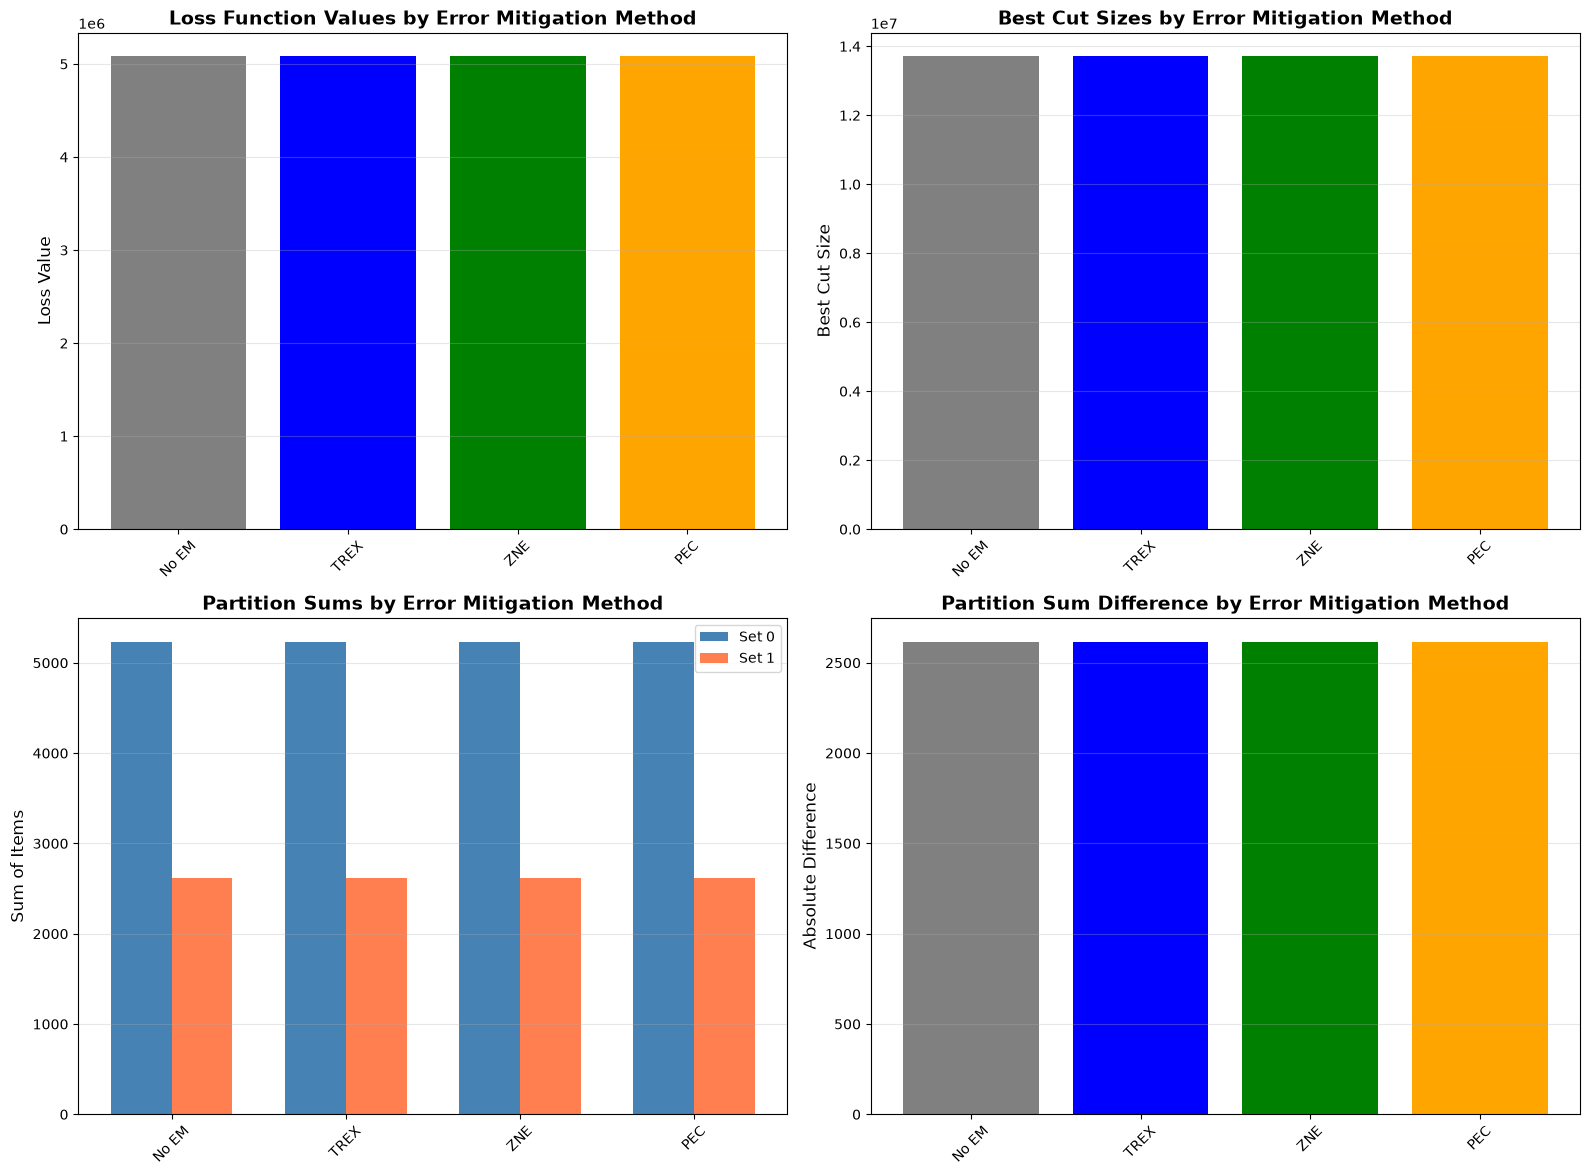


DETAILED RESULTS:

No EM:
  Loss: 5081012.01
  Best Cut: 13705230.00
  Partitions: 106 vs 54 nodes
  Difference in the sums of the partitions: 2617
  Set 0: [51, 92, 14, 71, 60, 20, 82, 86, 87, 99]...
  Set 1: [74, 74, 87, 29, 75, 57, 41, 91, 61, 46]...

TREX:
  Loss: 5081012.01
  Best Cut: 13705230.00
  Partitions: 106 vs 54 nodes
  Difference in the sums of the partitions: 2617
  Set 0: [51, 92, 14, 71, 60, 20, 82, 86, 87, 99]...
  Set 1: [74, 74, 87, 29, 75, 57, 41, 91, 61, 46]...

ZNE:
  Loss: 5081012.01
  Best Cut: 13705230.00
  Partitions: 106 vs 54 nodes
  Difference in the sums of the partitions: 2617
  Set 0: [51, 92, 14, 71, 60, 20, 82, 86, 87, 99]...
  Set 1: [74, 74, 87, 29, 75, 57, 41, 91, 61, 46]...

PEC:
  Loss: 5081012.01
  Best Cut: 13705230.00
  Partitions: 106 vs 54 nodes
  Difference in the sums of the partitions: 2617
  Set 0: [51, 92, 14, 71, 60, 20, 82, 86, 87, 99]...
  Set 1: [74, 74, 87, 29, 75, 57, 41, 91, 61, 46]...


In [56]:
# Step 1: Analyze baseline (No Error Mitigation)
results = {}
results["No EM"] = analyze_error_mitigation_result(
    loss=loss_no_em,
    experiment_result=experiment_no_em,
    partition_graph=partition_graph_large,
    numbers=numbers_large,  # List of actual numbers being partitioned
)

# Step 2: Analyze TREX with baseline comparison
results["TREX"] = analyze_error_mitigation_result(
    loss=loss_trex,
    experiment_result=experiment_trex,
    partition_graph=partition_graph_large,
    numbers=numbers_large,
)

# Step 3: Analyze ZNE + GT with baseline comparison
results["ZNE"] = analyze_error_mitigation_result(
    loss=loss_zne,
    experiment_result=experiment_zne,
    partition_graph=partition_graph_large,
    numbers=numbers_large,
)

# Step 4: Analyze PEC + GT with baseline comparison
results["PEC"] = analyze_error_mitigation_result(
    loss=loss_pec,
    experiment_result=experiment_pec,
    partition_graph=partition_graph_large,
    numbers=numbers_large,
)

# Step 5: Create comparison dataframe
comparison_df = compare_error_mitigation_methods(results, baseline_key="No EM")

# Step 6: Print summary with key findings
print_comparison_summary(comparison_df)

# Step 7: Plot comprehensive visualizations
plot_error_mitigation_comparison(comparison_df)

# Access individual results:
print("\n" + "=" * 80)
print("DETAILED RESULTS:")
print("=" * 80)

for method_name, result in results.items():
    print(f"\n{method_name}:")
    print(f"  Loss: {result['loss']:.2f}")
    print(f"  Best Cut: {result['best_cut']:.2f}")
    print(f"  Partitions: {result['par0_size']} vs {result['par1_size']} nodes")
    print(f"  Difference in the sums of the partitions: {result['difference']}")
    print(
        f"  Set 0: {result['set0'][:10]}..."
        if len(result["set0"]) > 10
        else f"  Set 0: {result['set0']}"
    )
    print(
        f"  Set 1: {result['set1'][:10]}..."
        if len(result["set1"]) > 10
        else f"  Set 1: {result['set1']}"
    )

    if "loss_improvement_pct" in result:
        print(f"  Improvement: {result['loss_improvement_pct']:.2f}%")
        print(f"  Cut Difference: {result['cut_diff']:.2f}")

##### Your results should look similar to those below. These were obtained from a previous job run on `ibm_pittsburgh`.

<div style="text-align:center;">
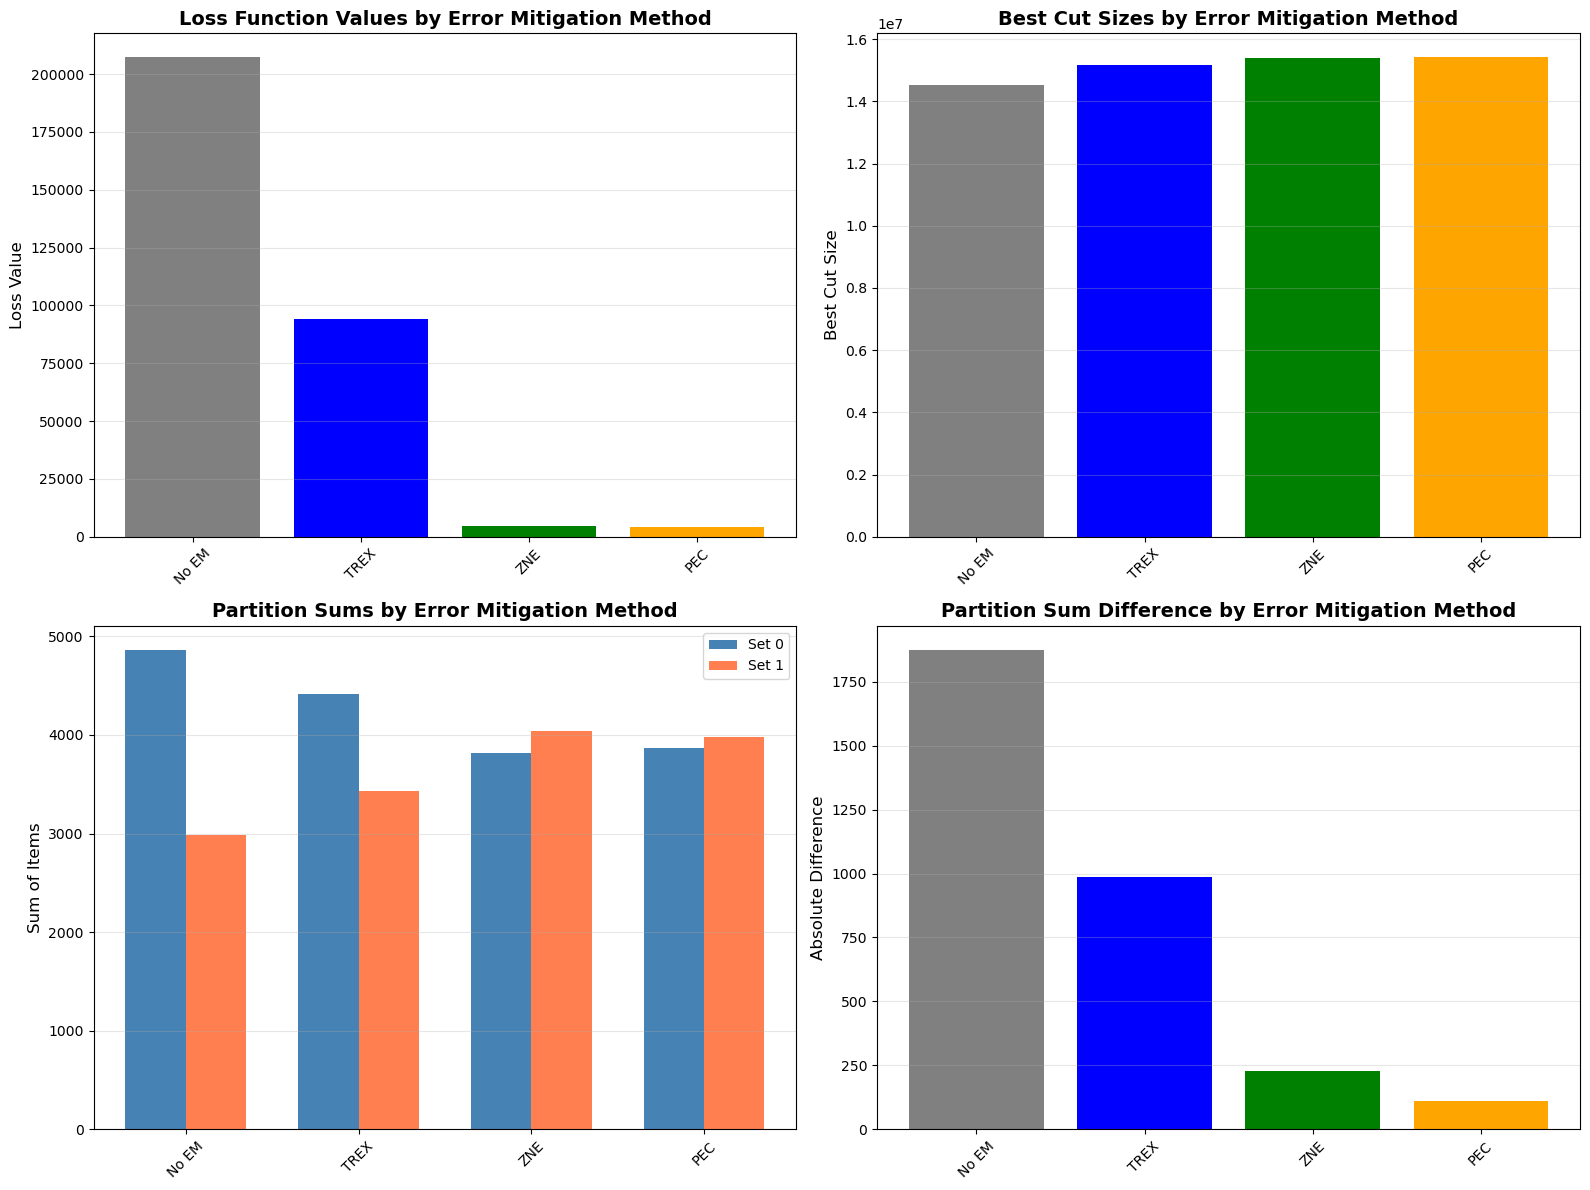
</div>

In [57]:
estimator_options_list = [
    est_options_no_em,
    est_options_trex,
    est_options_zne,
    est_options_pec,
]
jobs_est_list = [job_no_em, job_trex, job_zne, job_pec]

The grader cell below will verify that your jobs correctly apply the previously defined `EstimatorOptions` and assess the quality of your results to confirm you obtained a valid solution to the partition problem.

In [ ]:
## Verify your answer ##
# Original call:
# grade_lab4a_ex4(estimator_options_list, jobs_est_list)
print("SKIPPED (local phase): grade_lab4a_ex4 — run in David's session")


SKIPPED (local phase): grade_lab4a_ex4 — run in David's session


## Conclusion

Congratulations on completing Lab 4a! 🎉

In this lab, you explored the partition problem and learned how to formulate it as a QUBO problem suitable for current quantum computers using the QAOA algorithm. You have also experienced how advanced error mitigation and suppression techniques can significantly improve QAOA performance on real quantum hardware. Additionally, you implemented smart encoding strategies that reduce the qubit requirements, enabling you to solve problem instances on current QPUs that would be intractable with naive encoding approaches.

This Lab serves as a demonstration that a combination of the adequate quantum algorithm combined with tailored error-handling strategies and efficient encodings could brings us one step closer to solving real-world problems and demonstrating quantum advantage for classically verifiable problems.


In [59]:
# ── Track 1 build: dump the headline numbers to results/notebook-summary.json ──
import json as _json
from pathlib import Path as _Path

_summary = {
    "section2_sampler_best": {
        "key": best_key,
        "label": best_result["label"],
        "bitstring": "".join(str(b) for b in best_result["bitstring"]),
        "difference": best_result["difference"],
    },
    "section2_differences": {
        "v1_no_mitigation": difference_v1,
        "v2_suppression_only": difference_v2,
        "v3_m3_only": difference_v3,
        "v4_m3_plus_suppression": difference_v4,
    },
    "section4_pce_n160": {
        "loss_no_em": float(loss_no_em),
        "loss_trex": float(loss_trex),
        "loss_zne": float(loss_zne),
        "loss_pec": float(loss_pec),
        "decoded": {
            k: {
                "difference": (int(v["difference"]) if v.get("difference") is not None else None),
                "loss": float(v["loss"]),
            }
            for k, v in results.items()
        },
    },
}
_Path("results").mkdir(exist_ok=True)
_Path("results/notebook-summary.json").write_text(_json.dumps(_summary, indent=2, default=str))
print(_json.dumps(_summary, indent=2, default=str))


{
  "section2_sampler_best": {
    "key": "v4",
    "label": "VERSION 4: M3 + Error Suppression",
    "bitstring": "111100",
    "difference": 0
  },
  "section2_differences": {
    "v1_no_mitigation": 0,
    "v2_suppression_only": 0,
    "v3_m3_only": 0,
    "v4_m3_plus_suppression": 0
  },
  "section4_pce_n160": {
    "loss_no_em": 5081012.011353109,
    "loss_trex": 5081012.011353109,
    "loss_zne": 5081012.011353109,
    "loss_pec": 5081012.011353109,
    "decoded": {
      "No EM": {
        "difference": 2617,
        "loss": 5081012.011353109
      },
      "TREX": {
        "difference": 2617,
        "loss": 5081012.011353109
      },
      "ZNE": {
        "difference": 2617,
        "loss": 5081012.011353109
      },
      "PEC": {
        "difference": 2617,
        "loss": 5081012.011353109
      }
    }
  }
}
